# Facial expression recognition with PyTorch

Train a CNN + MLP on 48 x 48 grayscale FER2013 images. The seven classes are angry, disgust, fear, happy, sad, surprise, and neutral. Training uses data augmentation and early stopping based on validation loss.

## Import libraries

In [3]:
import sys
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset, TensorDataset
from torchvision.transforms import InterpolationMode, RandomAffine
from torchvision.transforms import functional as TF

cwd = Path.cwd()
utility_candidates = (
    cwd,
    *(parent / "4. Training Utilities" for parent in (cwd, *cwd.parents)),
    cwd / "BTL03" / "4. Training Utilities",
)
utility_dir = next(path for path in utility_candidates if (path / "shared_training.py").is_file())
sys.path.insert(0, str(utility_dir))
from shared_training import run_epoch

use_cuda = True
device = torch.device("cuda" if use_cuda and torch.cuda.is_available() else "cpu")
emotions = ("angry", "disgust", "fear", "happy", "sad", "surprise", "neutral")
num_classes = len(emotions)

## 1. Load FER2013

Place `fer2013_training_onehot.csv` and `fer2013_publictest_onehot.csv` in the Training Utilities folder. The [source notebook links to these data files](https://drive.google.com/drive/folders/0BxINLo5jshCRbXpRcnl2SjJkdlk?resourcekey=0-7qr7Ro7hgkmFknsN1yParQ&usp=sharing). Each row contains 2,304 pixel values followed by seven one-hot label values. The PublicTest split serves as both validation data and the final evaluation set, as in the source notebook.

In [4]:
def load_fer2013(csv_path):
    rows = np.loadtxt(csv_path, delimiter=",", dtype=np.float32, ndmin=2)
    images = np.ascontiguousarray(rows[:, :2304].reshape(-1, 1, 48, 48))
    labels = rows[:, 2304:2304 + num_classes].argmax(axis=1)
    return torch.from_numpy(images), torch.as_tensor(labels, dtype=torch.long)


x_training, y_training = load_fer2013(utility_dir / "fer2013_training_onehot.csv")
x_testing, y_testing = load_fer2013(utility_dir / "fer2013_publictest_onehot.csv")

print(f"Train: {len(x_training)} images")
print(f"PublicTest: {len(x_testing)} images")

Train: 28709 images
PublicTest: 3589 images


## 2. Define the CNN + MLP

In [5]:
class EmotionCNN(nn.Sequential):
    def __init__(self, num_classes):
        super().__init__(
            nn.Conv2d(1, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Dropout(0.25),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3),
            nn.ReLU(),
            nn.Conv2d(128, 218, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(218, 218, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Dropout(0.25),
            nn.Flatten(),
            nn.Linear(218 * 9 * 9, 1024),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(1024, num_classes),
        )

        # Match the default Keras kernel and bias initializers.
        for layer in self:
            if isinstance(layer, (nn.Conv2d, nn.Linear)):
                nn.init.xavier_uniform_(layer.weight)
                nn.init.zeros_(layer.bias)


model = EmotionCNN(num_classes).to(device)
print(model)
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters()):,}")

EmotionCNN(
  (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
  (3): ReLU()
  (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (5): Dropout(p=0.25, inplace=False)
  (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (7): ReLU()
  (8): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1))
  (9): ReLU()
  (10): Conv2d(128, 218, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (11): ReLU()
  (12): Conv2d(218, 218, kernel_size=(3, 3), stride=(1, 1))
  (13): ReLU()
  (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (15): Dropout(p=0.25, inplace=False)
  (16): Flatten(start_dim=1, end_dim=-1)
  (17): Linear(in_features=17658, out_features=1024, bias=True)
  (18): ReLU()
  (19): Dropout(p=0.5, inplace=False)
  (20): Linear(in_features=1024, out_features=7, bias=True)
)
Trainable parameters: 19,028,287


## 3. Train with augmentation and early stopping

Training images can rotate by up to 45 degrees, shift by up to 20% along either axis, and flip horizontally with 50% probability. Replicated edge pixels preserve the border fill behavior of the source. PublicTest images are used as loaded.

Early stopping ends training after five consecutive epochs without a decrease in validation loss. Evaluation uses the weights from the last completed epoch.

In [6]:
class AugmentedFER2013(Dataset):
    def __init__(self, images, labels):
        self.images = images
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        image = self.images[index]
        _, height, width = image.shape
        angle, translation, scale, shear = RandomAffine.get_params(
            [-45.0, 45.0], [0.2, 0.2], None, None, [width, height]
        )

        # Pad before the affine transform so samples beyond the image use its edge values.
        padding = max(height, width) // 2
        padded = TF.pad(image, padding, padding_mode="edge")
        transformed = TF.affine(
            padded, angle, translation, scale, shear, interpolation=InterpolationMode.BILINEAR
        )
        image = TF.center_crop(transformed, [height, width])
        if torch.rand(()) < 0.5:
            image = TF.hflip(image)
        return image, self.labels[index]


batch_size = 128
train_loader = DataLoader(
    AugmentedFER2013(x_training, y_training), batch_size=batch_size, shuffle=True
)
publictest_loader = DataLoader(TensorDataset(x_testing, y_testing), batch_size=batch_size)

In [7]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, eps=1e-7)
epochs = 100
patience = 5

history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}
best_val_loss = float("inf")
epochs_without_improvement = 0
starting_time = perf_counter()

for epoch in range(1, epochs + 1):
    train_metrics = run_epoch(model, train_loader, criterion, device, optimizer)
    val_metrics = run_epoch(model, publictest_loader, criterion, device)
    val_loss = val_metrics["loss"]

    history["loss"].append(train_metrics["loss"])
    history["accuracy"].append(train_metrics["accuracy"])
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_metrics["accuracy"])
    print(
        f"Epoch [{epoch}/{epochs}] - loss: {train_metrics['loss']:.4f} "
        f"- accuracy: {train_metrics['accuracy']:.2%} - val_loss: {val_loss:.4f} "
        f"- val_accuracy: {val_metrics['accuracy']:.2%}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= patience:
            print(f"Early stopping at epoch {epoch}")
            break

print(f"> Training time: {(perf_counter() - starting_time) / 60:.4f} minutes")

Epoch [1/100] - loss: 2.2391 - accuracy: 23.38% - val_loss: 1.8651 - val_accuracy: 25.05%
Epoch [2/100] - loss: 1.8213 - accuracy: 24.31% - val_loss: 1.8357 - val_accuracy: 25.16%
Epoch [3/100] - loss: 1.8092 - accuracy: 25.13% - val_loss: 1.8101 - val_accuracy: 26.78%
Epoch [4/100] - loss: 1.8003 - accuracy: 25.53% - val_loss: 1.7905 - val_accuracy: 25.75%
Epoch [5/100] - loss: 1.7908 - accuracy: 25.43% - val_loss: 1.7551 - val_accuracy: 30.09%
Epoch [6/100] - loss: 1.7752 - accuracy: 26.68% - val_loss: 1.7251 - val_accuracy: 30.40%
Epoch [7/100] - loss: 1.7659 - accuracy: 27.11% - val_loss: 1.7252 - val_accuracy: 30.96%
Epoch [8/100] - loss: 1.7511 - accuracy: 27.82% - val_loss: 1.6587 - val_accuracy: 33.49%
Epoch [9/100] - loss: 1.7288 - accuracy: 29.54% - val_loss: 1.6424 - val_accuracy: 34.33%
Epoch [10/100] - loss: 1.7149 - accuracy: 30.40% - val_loss: 1.6021 - val_accuracy: 37.14%
Epoch [11/100] - loss: 1.6831 - accuracy: 32.17% - val_loss: 1.5435 - val_accuracy: 37.34%
Epoch [1

## 4. Evaluate and predict a facial expression

In [8]:
score = run_epoch(model, publictest_loader, criterion, device)
print("Test loss:", score["loss"])
print("Test accuracy:", score["accuracy"])

Test loss: 1.0213543720881764
Test accuracy: 0.619671217609362


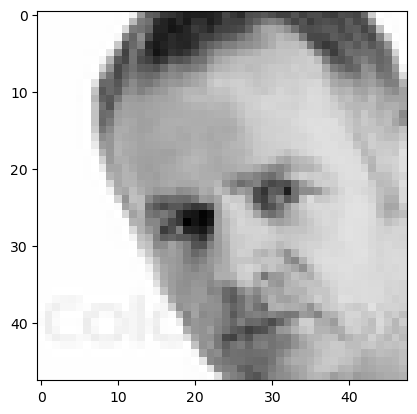

> Testing image index: 2866
> True emotion: fear
> Predicted emotion: angry


In [9]:
image_index = np.random.randint(len(x_testing))
sample = x_testing[image_index]
true_label = y_testing[image_index].item()

model.eval()
with torch.inference_mode():
    predicted_label = model(sample.unsqueeze(0).to(device)).argmax(dim=1).item()

plt.imshow(sample.squeeze(0), cmap="gray")
plt.show()
print(f"> Testing image index: {image_index}")
print(f"> True emotion: {emotions[true_label]}")
print(f"> Predicted emotion: {emotions[predicted_label]}")